# Health vs. Price: How to Be a Smart Grocery Shopper
### What Open Food Facts and Open Prices reveal about U.S. packaged groceries
**BA780 · Cohort B · Team 2 (B02) · Final deliverable**

**Audience:** everyday grocery shoppers, especially those on a budget who have been told that eating well costs more.

**Goal:** turn open data into a few simple rules for paying less while eating better, with price at the centre of every decision.

**Data**
- [Open Food Facts product database](https://huggingface.co/datasets/openfoodfacts/product-database), U.S. products (`off_products_us.csv`, rebuilt with `B02-Data-Pull-v2.ipynb`)
- [Open Prices](https://huggingface.co/datasets/openfoodfacts/open-prices), U.S. stores (`off_prices_us.csv`)
- Open Food Facts food-group taxonomy (`food_groups.json`)

All three are open data (ODbL 1.0) and free to download. Our copies are in the team Drive (`BA780 Team 2/Codebase/input_data/`).


**Contents:**

- Executive summary
- Problem and hypotheses
- Data and cleaning
- Theme 1: know your aisle
- Theme 2: the greener choice
- Theme 3: healthy doesn't cost more
- Theme 4: know what you pay for
- Theme 5: shop the store, not just the shelf
- The smart-shopper playbook
- Risks
- Limitations
- Challenges
- Next steps: a gamified swap app
- References
- GenAI disclosure

# Executive summary
**The belief we tested:** "eating healthy is expensive." We matched 988,445 U.S. products from Open Food Facts with 39,725 shelf prices from Open Prices (85% of them from California, mostly Bay Area stores) and compared prices **per 100 g within the same aisle**, the way a shopper actually chooses.

**What we found:** in the stores we could measure, healthy food is not what costs more. Shoppers overpay for brands, packaging, and energy-dense treats, not for nutrition.
- Per 100 g, Nutri-Score A/B products cost **17% less** than D/E products in the same aisle, and no aisle shows a significant health premium.
- The healthiest aisles (legumes, vegetables, milk and yogurt, plain cereals, fruit) are also the cheapest, at about **$1 per 100 g**. Chocolate, biscuits, nuts, and cheese cost $2.30-6.
- Store brands cost **42% less** per 100 g than national brands in the same aisle, and are healthier in 10 of 14 aisles.
- The same product varies by a median of **14%** between the cheapest and dearest store.
- Low-impact (greener) products are healthier and cost no more (7% less per 100 g).

**The smart-shopper rules**
1. **Read the price per 100 g, not the package price.**
2. **Swap down a grade, not up in price.** For 89% of D/E products, our prototype finds a healthier, cheaper, similar product in the same aisle.
3. **Try the store brand first.**
4. **Know your store.** The same item can be 10% cheaper or dearer depending on where you buy it.
5. **Don't let promotion tags steer the cart.** They cluster in the snack and sweet aisles.

**Next step:** a gamified swap app built on Open Prices. You scan a product, see whether it is a good price for its aisle, get a healthier and cheaper swap, and earn points. Every price tag you photograph also grows the open price data the app relies on.

# 1. Problem and hypotheses
**The shopper's question:** can I eat healthier without paying more, and where does my grocery money actually go?

**Why it matters:** budget-conscious shoppers are told that healthy food costs more, so many stop trying. If that belief is wrong, or only true in a few aisles, shoppers can eat better and save money at the same time.

Each theme tests one or two hypotheses, each with the direction we expected and the shopping decision it informs.

| Theme | # | Hypothesis (expected direction) | Test | Shopping decision it informs |
|---|---|---|---|---|
| 1 | H1 | The aisle (food group) explains more of a product's Nutri-Score than its brand | R², food group vs brand | Where to compare products |
| 1 | H2 | Aisles with more ultra-processed products have fewer Nutri-Score A/B products | Spearman correlation across food groups | Which aisles need the most care |
| 2 | H3 | In the same aisle, low-impact products (Green A/B) are more often Nutri-Score A/B than high-impact ones (D-F) | % A/B difference per aisle; price ratio | Whether the greener choice is also the healthy, affordable one |
| 3 | H4 | In the same aisle, Nutri-Score A/B products cost **more** per 100 g than D/E products | Price ratio with 95% CI, 30+ products per side | Whether a healthier swap costs extra |
| 4 | H5 | In the same aisle, less-processed products (NOVA 1-3) cost more per 100 g than ultra-processed ones | Price ratio with 95% CI | Whether avoiding ultra-processed food costs extra |
| 4 | H6 | Organic products cost more per 100 g but are not healthier | Price ratio; % A/B gap | Whether organic is worth it |
| 5 | H7 | Store brands cost less per 100 g than national brands, with no worse Nutri-Score | Price ratio; % A/B gap | Store brand or national brand |
| 5 | H8 | Ultra-processed products are on promotion more often, even in the same store and aisle | % on promotion, same store and aisle | How much to trust promotion tags |

**Scope of the price results:** Themes 3-5 use prices from a small number of mostly Bay Area stores. They describe those stores, not U.S. prices as a whole (see Limitations).

# 2. Data and cleaning
### 2.1 Setup and loading

In [1]:
# Importing libraries
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", 30)
sns.set_theme(style="whitegrid")

# Mounting the google drive folder for reading input data
from google.colab import drive
drive.mount("/content/drive")
path = "/content/drive/MyDrive/BA780 Team 2/Codebase/input_data/"

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
# Hardcoding colours for Nutri-Score from A-good to E-bad
nutri_colors = ["#1c5cab", "#6da7ec", "#b4b2ab", "#ec8a85", "#b8312f"]

# Function to  compare the prices of two groups of products
# Prices are skewed, so we compare the average of the log prices (ratio of geometric means).
# ratio = 0.8 means group 'a' costs 20% less than group 'b'
def price_ratio(a, b):
    test = stats.ttest_ind(np.log(a), np.log(b), equal_var=False)
    ci = test.confidence_interval()
    ratio = np.exp(np.log(a).mean() - np.log(b).mean())
    return ratio, np.exp(ci.low), np.exp(ci.high), test.pvalue

In [3]:
# Load the input data
product_cols = ["code", "product_name", "brands", "categories_tags", "food_groups_tags", "nutriscore_grade",
                "nova_group", "environmental_score_grade", "energy-kcal_100g", "sugars_100g", "fat_100g",
                "saturated-fat_100g", "fiber_100g", "proteins_100g", "salt_100g", "size_g_ml", "is_organic",
                "in_us_catalog"]

products_raw = pd.read_csv(path + "off_products_us.csv", usecols=product_cols, dtype={"code": str})

prices_raw = pd.read_csv(path + "off_prices_us.csv", dtype={"product_code": str})

with open(path + "food_groups.json") as f:
    food_groups = json.load(f)

print("products:", products_raw.shape)
print("prices:", prices_raw.shape)
print("food groups:", len(food_groups))

/tmp/ipykernel_15245/520335660.py:7: DtypeWarning: Columns (28) have mixed types. Specify dtype option on import or set low_memory=False.
  products_raw = pd.read_csv(path + "off_products_us.csv", usecols=product_cols, dtype={"code": str})


products: (988447, 18)
prices: (42822, 48)
food groups: 91


### 2.2 Cleaning
Products: barcodes padded to 13 digits, placeholders such as "unknown" set to missing, impossible nutrient values removed, official food-group names attached, and package sizes outside 20 g to 5 kg dropped. Prices: barcode prices in USD only, duplicate price tags removed, regular (pre-discount) price used, and non-grocery prices removed.

In [4]:
###### Clean the products file

products = products_raw.copy()

# Pad barcodes to 13 digits with leading zeroes
products["code"] = products["code"].str.strip()
short = products["code"].str.isdigit() & (products["code"].str.len() < 13)
products.loc[short, "code"] = products.loc[short, "code"].str.zfill(13)
products = products.drop_duplicates("code")

# Assign brand to be the first brand in the list
products["brand"] = products["brands"].str.split(",").str[0].str.strip()

# scores: Converting "unknown" and "not-applicable" to NaN  and A+ green score changed to A
products["nutriscore"] = products["nutriscore_grade"].str.upper()
products.loc[~products["nutriscore"].isin(["A", "B", "C", "D", "E"]), "nutriscore"] = np.nan
products["green_score"] = products["environmental_score_grade"].replace("a-plus", "a").str.upper()
products.loc[~products["green_score"].isin(["A", "B", "C", "D", "E", "F"]), "green_score"] = np.nan
products.loc[~products["nova_group"].isin([1, 2, 3, 4]), "nova_group"] = np.nan

# Removing impossible nutrient values (below 0, above 100 g per 100 g, above 900 kcal) to NaN.
for col in ["sugars_100g", "fat_100g", "saturated-fat_100g", "fiber_100g", "proteins_100g", "salt_100g"]:
    products.loc[(products[col] < 0) | (products[col] > 100), col] = np.nan
products.loc[(products["energy-kcal_100g"] < 0) | (products["energy-kcal_100g"] > 900), "energy-kcal_100g"] = np.nan

# Food group names show up as a hierarchial list e.g. "en:milk-and-dairy-products|en:cheese"
# level 1 = first tag (Milk and dairy products), level 2 = second tag (Cheese). We use level 2 when there is one.
names = {}
for tag in food_groups:
    names[tag] = food_groups[tag]["name"]["en"].replace("‚", ",")
products["food_group_l1"] = products["food_groups_tags"].str.split("|").str[0].map(names)
products["food_group"] = products["food_groups_tags"].str.split("|").str[1].map(names)
products["food_group"] = products["food_group"].fillna(products["food_group_l1"])

# package size: keep 20 g to 5 kg (sizes like 1 g or 200 oz of cookies are entry errors)
products.loc[~products["size_g_ml"].between(20, 5000), "size_g_ml"] = np.nan

# creating 1/0 flags to for Nutri-Score A or B, and ultra-processed (NOVA 4)
products["is_AB"] = products["nutriscore"].map({"A": 1, "B": 1, "C": 0, "D": 0, "E": 0})
products["is_ultra"] = products["nova_group"].map({1: 0, 2: 0, 3: 0, 4: 1})

print("clean products:", len(products))

clean products: 988445


In [5]:
#### Clean the prices file

# Keeping the prices of products with a barcode, in US dollars
# CATEGORY rows are loose produce so removed them
prices = prices_raw[(prices_raw["type"] == "PRODUCT") & (prices_raw["currency"] == "USD")].copy()

# Pad barcodes to 13 digits with leading zeroes
prices["code"] = prices["product_code"].str.strip()
short = prices["code"].str.isdigit() & (prices["code"].str.len() < 13)
prices.loc[short, "code"] = prices.loc[short, "code"].str.zfill(13)

# Dedup for same price tag uploaded twice
prices = prices.drop_duplicates(["code", "location_id", "date", "price"])

# for items on sale we use the price before the discount, so promotions don't skew the comparisons
prices["regular_price"] = prices["price"]
on_sale = prices["price_is_discounted"] == True
prices.loc[on_sale, "regular_price"] = prices.loc[on_sale, "price_without_discount"]

# drop non-grocery items (e.g. $3,199 TVs at Costco) and missing prices
prices = prices[prices["regular_price"].between(0.10, 100)].copy()

# extracting store name and state from the address
prices["store"] = prices["location_osm_display_name"].str.split(",").str[0]
prices["state"] = prices["location_osm_display_name"].str.extract(r",\s*([A-Za-z ]+),\s*[\d-]+,\s*United States$")[0]
prices = prices[["code", "date", "store", "state", "owner", "price", "regular_price", "price_is_discounted"]]

print("clean price observations:", len(prices), "for", prices["code"].nunique(), "barcodes")
print(f"from California: {(prices['state'] == 'California').mean():.0%}")
print(f"from the top contributor: {prices['owner'].value_counts(normalize=True).iloc[0]:.0%}")

clean price observations: 39725 for 26573 barcodes
from California: 85%
from the top contributor: 93%


### 2.3 Joining products and prices

In [6]:
# Join product and prices data on barcode
product_price = prices.groupby("code")["regular_price"].median().reset_index()
product_price.columns = ["code", "price"]
df = products.merge(product_price, on="code")

# Converting prices to price per 100 g (or 100 ml) so a 12 oz and a 32 oz jar can be compared
df["price_100g"] = df["price"] / df["size_g_ml"] * 100
df.loc[~df["price_100g"].between(0.05, 50), "price_100g"] = np.nan   # e.g. $24 for "1 g" of peanut butter

print(f"{product_price['code'].isin(products['code']).mean():.1%} of priced barcodes match a product")
print("priced products:", len(df))
print("with price per 100 g:", df["price_100g"].notna().sum())

86.1% of priced barcodes match a product
priced products: 22882
with price per 100 g: 9858


86% of priced barcodes match a product. Package size is known for 43% of priced products, which limits the per-100 g analyses to about 10,000 products (and 5,752 foods with a food group).

---
# Theme 1. Know your aisle: it decides most of what you get
A price comparison only makes sense between products a shopper would actually swap. So first: what is in the data, what does each aisle look like, and does the aisle or the brand decide how healthy a product is?

### Data funnel and description

In [7]:
# Table 1. Data funnel
not_food = ["Beverages", "Alcoholic beverages", "Baby foods and milks"]

# Foods in food groups with 2,000+ products
foods = products[products["food_group"].notna() & ~products["food_group_l1"].isin(not_food)]
group_size = foods["food_group"].value_counts()
foods = foods[foods["food_group"].isin(group_size[group_size >= 2000].index)]

# Priced foods with a price per 100 g and drinks left out as tea bags, juice and water aren't comparable per 100 g
priced = df[df["food_group"].notna() & df["price_100g"].notna() & ~df["food_group_l1"].isin(not_food)].copy()

# price index = log price per 100 g minus the average log price of the food group
# exp(log_index) = 1.2 means 20% more expensive than a typical product in the same aisle
priced["log_price"] = np.log(priced["price_100g"])
priced["log_index"] = priced["log_price"] - priced.groupby("food_group")["log_price"].transform("mean")

funnel = pd.DataFrame([
    ["Products file (v2 pull)", "U.S.-tagged products + any barcode with a U.S. price", len(products_raw)],
    ["Clean product catalog", "unique barcodes, placeholders removed", len(products)],
    ["  with an official food group", "food_groups_tags", products["food_group"].notna().sum()],
    ["  with a Nutri-Score", "grade A-E", products["nutriscore"].notna().sum()],
    ["  with a NOVA group", "1-4", products["nova_group"].notna().sum()],
    ["  with a Green-Score", "grade A-F", products["green_score"].notna().sum()],
    ["  with a package size", "20 g - 5 kg", products["size_g_ml"].notna().sum()],
    ["Aisle analysis set (Themes 1-2)", "foods, groups with 2,000+ products", len(foods)],
    ["Price observations (raw)", "Open Prices, U.S. stores", len(prices_raw)],
    ["Clean price observations", "barcode, USD, regular price, $0.10-$100", len(prices)],
    ["Priced products in the catalog", "barcode join", len(df)],
    ["  with price per 100 g", "package size known", df["price_100g"].notna().sum()],
    ["Price analysis set (Themes 3-5)", "foods with price per 100 g + food group", len(priced)],
    ["  with a Nutri-Score", "", priced["nutriscore"].notna().sum()],
], columns=["Stage", "Rule", "Rows"])
funnel["% of clean catalog"] = (funnel["Rows"] / len(products) * 100).round(1)
funnel.loc[[0, 8, 9], "% of clean catalog"] = np.nan   # these rows are raw / price rows, not catalog products
funnel

,Stage,Rule,Rows,% of clean catalog
0,Products file (v2 pull),U.S.-tagged products + any barcode with a U.S....,988447,NaN
1,Clean product catalog,"unique barcodes, placeholders removed",988445,100.0
2,with an official food group,food_groups_tags,290927,29.4
3,with a Nutri-Score,grade A-E,384579,38.9
4,with a NOVA group,1-4,393852,39.8
5,with a Green-Score,grade A-F,55386,5.6
6,with a package size,20 g - 5 kg,179715,18.2
7,Aisle analysis set (Themes 1-2),"foods, groups with 2,000+ products",234005,23.7
8,Price observations (raw),"Open Prices, U.S. stores",42822,NaN
9,Clean price observations,"barcode, USD, regular price, $0.10-$100",39725,NaN


The official food group is the main bottleneck: 29% of products have one, because most products have no category at all. Prices exist for 2.3% of the catalog, and with both a package size and a food group only 0.6% (5,752 foods) are left for the price analysis.

In [8]:
# Table 2. How complete is each variable? (% of rows that are not missing)
cols = ["food_group", "nutriscore", "nova_group", "green_score", "is_organic", "size_g_ml",
        "energy-kcal_100g", "sugars_100g", "fat_100g", "proteins_100g", "fiber_100g", "salt_100g"]
coverage = pd.DataFrame({"catalog %": products[cols].notna().mean() * 100,
                         "priced products %": df[cols].notna().mean() * 100})
display(coverage.round(0))

# typical values
print("Nutri-Score share:", products["nutriscore"].value_counts(normalize=True).sort_index().round(2).to_dict())
print("NOVA share:", products["nova_group"].value_counts(normalize=True).sort_index().round(2).to_dict())
print(f"median price: ${df['price'].median():.2f} per package, ${df['price_100g'].median():.2f} per 100 g")
products[["size_g_ml", "energy-kcal_100g", "sugars_100g", "fat_100g", "proteins_100g", "fiber_100g", "salt_100g"]].describe().round(1)

,catalog %,priced products %
food_group,29.0,52.0
nutriscore,39.0,57.0
nova_group,40.0,70.0
green_score,6.0,28.0
is_organic,18.0,55.0
size_g_ml,18.0,43.0
energy-kcal_100g,84.0,87.0
sugars_100g,79.0,83.0
fat_100g,84.0,87.0
proteins_100g,85.0,88.0


Nutri-Score share: {'A': 0.14, 'B': 0.11, 'C': 0.19, 'D': 0.24, 'E': 0.32}
NOVA share: {1.0: 0.1, 2.0: 0.03, 3.0: 0.17, 4.0: 0.7}
median price: $5.99 per package, $1.97 per 100 g


,size_g_ml,energy-kcal_100g,sugars_100g,fat_100g,proteins_100g,fiber_100g,salt_100g
count,179715.0,832837.0,781828.0,834507.0,840295.0,667438.0,776879.0
mean,382.9,260.1,14.0,12.2,9.7,3.2,1.4
std,455.4,186.3,20.1,16.5,12.9,6.2,4.8
min,20.0,0.0,0.0,0.0,0.0,0.0,0.0
25%,113.4,97.0,0.7,0.0,0.8,0.0,0.1
50%,283.5,250.0,4.2,5.8,6.0,1.2,0.6
75%,453.6,393.0,20.0,18.4,13.6,3.6,1.4
max,5000.0,900.0,100.0,100.0,100.0,100.0,100.0


Priced products are better documented than the catalog as a whole (Nutri-Score 57% vs 39%), most likely because people photograph popular, well-known products in stores. The Green-Score covers only 6% of the catalog. The typical priced product costs \$5.99 per package and \$1.97 per 100 g.

The catalog leans unhealthy: 56% of products with a Nutri-Score are D or E, and 70% of products with a NOVA group are ultra-processed. Nutrients are right-skewed (sugar: mean 15.7 g, median 4.8 g per 100 g in foods), so we use medians and geometric means rather than plain averages.

In [9]:
# Table 3. Checking the product aisles coverage (level-1 food groups)
aisles = products.groupby("food_group_l1").agg(products=("code", "size"),
                                              with_nutriscore=("nutriscore", "count"),
                                              pct_A_B=("is_AB", "mean"),
                                              pct_ultra_processed=("is_ultra", "mean"),
                                              median_kcal=("energy-kcal_100g", "median"),
                                              median_sugar_g=("sugars_100g", "median"),
                                              median_salt_g=("salt_100g", "median"))
aisles["pct_of_products"] = aisles["products"] / aisles["products"].sum() * 100
aisles["pct_nutriscore"] = aisles["with_nutriscore"] / aisles["products"] * 100
aisles["pct_A_B"] = aisles["pct_A_B"] * 100
aisles["pct_ultra_processed"] = aisles["pct_ultra_processed"] * 100
aisles = aisles.sort_values("products", ascending=False)
aisles.round(1)

,products,with_nutriscore,pct_A_B,pct_ultra_processed,median_kcal,median_sugar_g,median_salt_g,pct_of_products,pct_nutriscore
food_group_l1,,,,,,,,,
Sugary snacks,61717,53996,2.1,86.9,400.0,40.9,0.4,21.2,87.5
Beverages,47118,39856,32.8,74.6,33.0,5.0,0.0,16.2,84.6
Cereals and potatoes,36397,32387,40.8,56.7,350.9,3.6,0.8,12.5,89.0
Fats and sauces,35113,31323,22.9,54.4,175.4,3.6,1.2,12.1,89.2
Milk and dairy products,26737,25032,23.7,62.4,219.5,4.4,0.5,9.2,93.6
Composite foods,26385,25088,20.4,83.4,206.0,2.3,1.2,9.1,95.1
"Fish, Meat, Eggs",23644,21534,39.3,63.1,164.7,0.0,1.4,8.1,91.1
Fruits and vegetables,21807,18996,77.8,21.6,50.0,4.0,0.1,7.5,87.1
Salty snacks,9673,8537,15.3,48.9,500.0,3.5,1.3,3.3,88.3


Sugary snacks are the largest aisle (21% of products with a food group) and the least healthy (2% A/B, 87% ultra-processed). Fruits and vegetables are the opposite (78% A/B, 22% ultra-processed).

### The Nutri-Score mix in each aisle

% Nutri-Score A or B: {'Pizza pies and quiches': 1.0, 'Biscuits and cakes': 2.0, 'Sweets': 3.0, 'Appetizers': 4.0, 'Cheese': 4.0, 'Processed meat': 5.0, 'Dressings and sauces': 17.0, 'Breakfast cereals': 18.0, 'Bread': 21.0, 'Sandwiches': 23.0, 'One-dish meals': 28.0, 'Meat': 38.0, 'Fats': 42.0, 'Nuts': 48.0, 'Milk and yogurt': 51.0, 'Cereals': 52.0, 'Fish and seafood': 68.0, 'Fruits': 73.0, 'Legumes': 75.0, 'Fruits and vegetables': 84.0, 'Vegetables': 85.0, 'Eggs': 93.0}


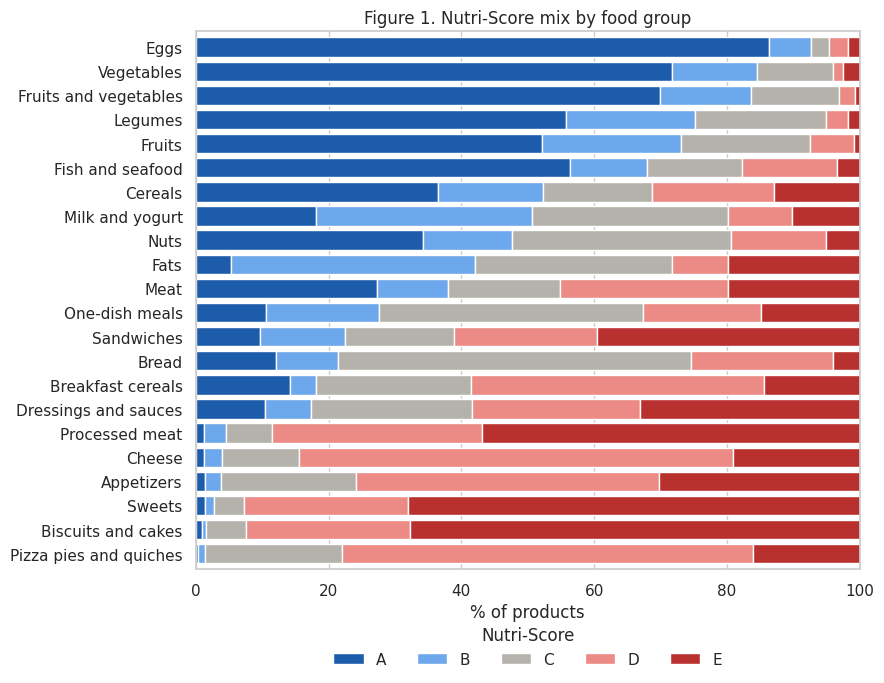

In [10]:
# Figure 1. Nutri-Score mix inside each food group
mix = pd.crosstab(foods["food_group"], foods["nutriscore"], normalize="index") * 100
mix = mix.loc[(mix["A"] + mix["B"]).sort_values().index]   # healthiest groups at the top
print("% Nutri-Score A or B:", (mix["A"] + mix["B"]).round(0).to_dict())

ax = mix.plot.barh(stacked=True, color=nutri_colors, figsize=(9, 7), width=0.8, edgecolor="white")
ax.set(title="Figure 1. Nutri-Score mix by food group", xlabel="% of products", ylabel="", xlim=(0, 100))
ax.legend(title="Nutri-Score", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.08), frameon=False)
plt.tight_layout()
plt.show()

How healthy is each aisle?

Takeaway: The aisle mostly decides how healthy a product is: 93% of eggs and 85% of vegetables score A/B, while about 90% of biscuits, sweets and processed meat score D/E. So the real choice is usually a one-grade swap within an aisle, not a jump from E to A. The aisles with the widest spread (meat, nuts, cereals, ready meals) are where reading the label makes the biggest difference.

### H1: the aisle matters more than the brand

In [11]:
# H1: does the food group (aisle) explain more of the Nutri-Score than the brand?
# only brands that sell in 3+ food groups and have 30+ scored products, so brand and aisle can be told apart
# R² = share of the variation in Nutri-Score (A=1 ... E=5) explained by the average of each aisle / brand
x = products.dropna(subset=["nutriscore", "food_group", "brand"]).copy()
x["score"] = x["nutriscore"].map({"A": 1, "B": 2, "C": 3, "D": 4, "E": 5})
x["brand"] = x["brand"].str.lower()
brand_size = x.groupby("brand")["score"].count()
brand_groups = x.groupby("brand")["food_group"].nunique()
x = x[x["brand"].isin(brand_size[(brand_size >= 30) & (brand_groups >= 3)].index)]

total = ((x["score"] - x["score"].mean()) ** 2).sum()
r2_aisle = 1 - ((x["score"] - x.groupby("food_group")["score"].transform("mean")) ** 2).sum() / total
r2_brand = 1 - ((x["score"] - x.groupby("brand")["score"].transform("mean")) ** 2).sum() / total
print(x["brand"].nunique(), "brands,", len(x), "products")
print(f"R² food group = {r2_aisle:.2f} | R² brand = {r2_brand:.2f}")

660 brands, 85172 products
R² food group = 0.40 | R² brand = 0.29


**Supported.** Among 660 brands that sell in 3+ aisles (85,172 products), the aisle explains 40% of the variation in Nutri-Score and the brand 29%. A "healthy" brand does not make its cookies healthy.

### H2: more ultra-processing, fewer healthy grades

Spearman rho = -0.77 (p = 0.0000, 22 food groups)


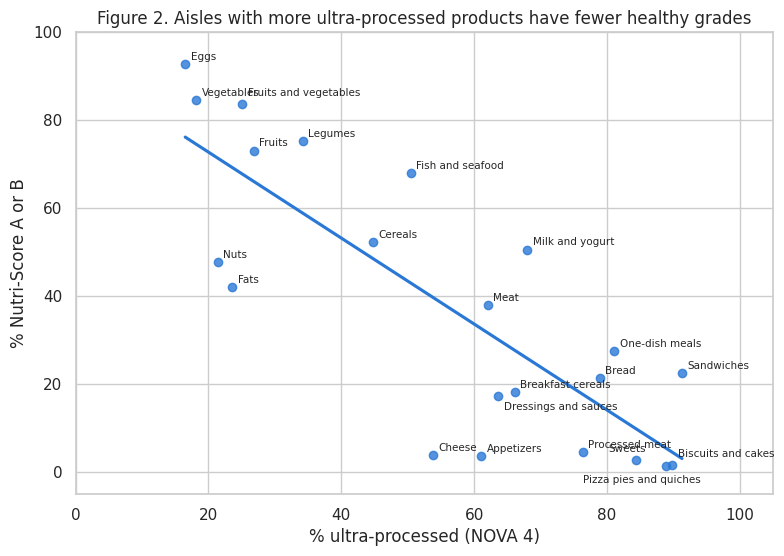

In [12]:
# Figure 2: The more ultra-processed an aisle, the fewer healthy products it has

## Creating scatter plot with correlation coefficient to look at the relationship
by_group = foods.groupby("food_group")[["is_AB", "is_ultra"]].mean() * 100
rho, p = stats.spearmanr(by_group["is_ultra"], by_group["is_AB"])
print(f"Spearman rho = {rho:.2f} (p = {p:.4f}, {len(by_group)} food groups)")

plt.figure(figsize=(9, 6))
sns.regplot(data=by_group, x="is_ultra", y="is_AB", ci=None, color="#2a78d6")

# a few labels moved manually so they don't overlap
move = {"Pizza pies and quiches": (-60, -12), "Biscuits and cakes": (4, 6), "Sweets": (-20, 6),
        "Dressings and sauces": (4, -10), "Fruits and vegetables": (4, 6)}
for name, row in by_group.iterrows():
    plt.annotate(name, (row["is_ultra"], row["is_AB"]), xytext=move.get(name, (4, 3)),
                 textcoords="offset points", fontsize=7.5)
plt.title("Figure 2. Aisles with more ultra-processed products have fewer healthy grades")
plt.xlabel("% ultra-processed (NOVA 4)")
plt.ylabel("% Nutri-Score A or B")
plt.xlim(0, 105)
plt.ylim(-5, 100)
plt.show()

Do aisles with more ultra-processed food have fewer healthy products?

Takeaway: Processing and nutrition move together: the more ultra-processed an aisle is, the fewer healthy products it has (rho = -0.77). The exceptions show that the two measures capture different things. Flavored yogurts are ultra-processed but still score well, while nuts and oils are barely processed but held back by fat. Shoppers need both labels, not one.

---
# Theme 2. The greener choice: healthier, and no more expensive
Only 6% of products have a Green-Score (45,481 have both scores), so this theme uses every product with both scores. The price check at the end uses the priced foods.

products with both scores: 45481
impact
Low impact (Green A/B)     39.0
Medium (Green C)           14.2
High impact (Green D-F)    30.2
dtype: float64


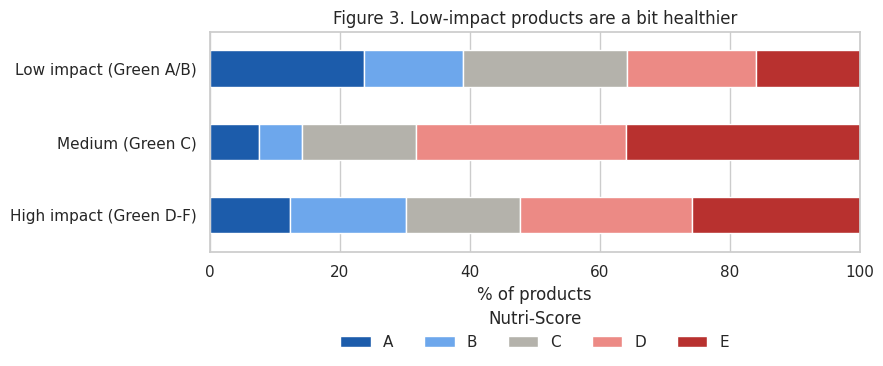

In [13]:
# Figure 3: Low-impact products are only slightly healthier across the whole store
# Products are grouped by Green-Score (low, medium, high impact), and each bar shows their Nutri-Score mix.
both_cat = products.dropna(subset=["nutriscore", "green_score"]).copy()
print("products with both scores:", len(both_cat))

impact = {"A": "Low impact (Green A/B)", "B": "Low impact (Green A/B)", "C": "Medium (Green C)",
          "D": "High impact (Green D-F)", "E": "High impact (Green D-F)", "F": "High impact (Green D-F)"}
both_cat["impact"] = both_cat["green_score"].map(impact)

# grades as numbers, for the correlation in Figure 5
both_cat["nutri_number"] = both_cat["nutriscore"].map({"A": 0, "B": 1, "C": 2, "D": 3, "E": 4})
both_cat["green_number"] = both_cat["green_score"].map({"A": 0, "B": 1, "C": 2, "D": 3, "E": 4, "F": 5})

mix = pd.crosstab(both_cat["impact"], both_cat["nutriscore"], normalize="index") * 100
mix = mix.loc[["Low impact (Green A/B)", "Medium (Green C)", "High impact (Green D-F)"]]
healthy_share = mix["A"] + mix["B"]
print(healthy_share.round(1))

ax = mix.plot.barh(stacked=True, color=nutri_colors, figsize=(9, 4), edgecolor="white")
ax.invert_yaxis()
ax.set(title="Figure 3. Low-impact products are a bit healthier", xlabel="% of products", ylabel="", xlim=(0, 100))
ax.legend(title="Nutri-Score", ncol=5, loc="upper center", bbox_to_anchor=(0.5, -0.2), frameon=False)
plt.tight_layout()
plt.show()

Are low-impact products healthier overall?

Takeaway:
Low-impact products are only slightly healthier (39% score A/B vs 30% for high-impact), and medium-impact products are the least healthy (14%). Therefore, Green-Score alone is a weak signal of health, so we should compare products within the same food group next to explore more meanigful links.

                      products  pct_healthy  pct_green
food_group                                            
Bread                     2159         25.4       97.8
Appetizers                3567          4.0       90.2
Vegetables                1426         84.9       86.4
Milk and yogurt           7769         57.0       82.7
Fruits                     950         71.1       73.7
Sweets                    3005          6.6       69.8
Legumes                   1503         70.8       69.0
Dressings and sauces      3570         14.0       58.3
One-dish meals             654         46.4       38.4
Cereals                   1718         69.7       33.5
Eggs                      1634         92.7       30.9
Biscuits and cakes        4381          1.9       13.4
Breakfast cereals         3787         18.2       12.5
Meat                       952         45.0        8.9
Fats                      2148         76.5        2.5
Processed meat             409          4.9        1.5
Fish and s

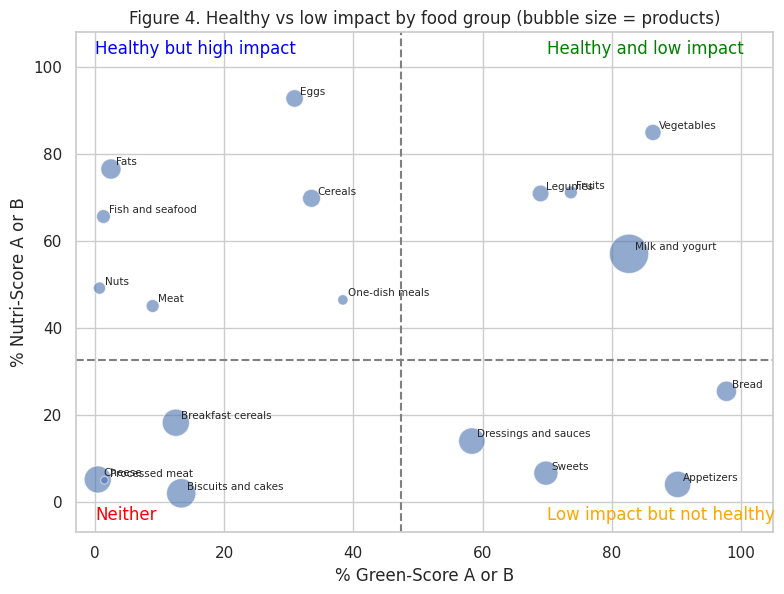

In [14]:
# Figure 4. Healthy vs low impact, one dot per food group (only includes groups with 300+ Green-Scored foods)

g_foods = foods.dropna(subset=["green_score"]).copy()
g_foods["is_green"] = g_foods["green_score"].isin(["A", "B"])

group_counts = g_foods["food_group"].value_counts()
keep_groups = group_counts[group_counts >= 300].index

group_summary = g_foods[g_foods["food_group"].isin(keep_groups)].groupby("food_group").agg(
    products=("code", "size"), pct_healthy=("is_AB", "mean"), pct_green=("is_green", "mean"))
group_summary["pct_healthy"] = group_summary["pct_healthy"] * 100
group_summary["pct_green"] = group_summary["pct_green"] * 100
print(group_summary.round(1).sort_values("pct_green", ascending=False))

plt.figure(figsize=(9, 6.5))
sns.scatterplot(data=group_summary, x="pct_green", y="pct_healthy", size="products", sizes=(30, 800),
                alpha=0.6, legend=False)
for name, row in group_summary.iterrows():
    plt.annotate(name, (row["pct_green"], row["pct_healthy"]), xytext=(4, 3), textcoords="offset points", fontsize=7.5)

# dashed lines = average of all products with both scores
plt.axvline(both_cat["green_score"].isin(["A", "B"]).mean() * 100, color="gray", linestyle="--")
plt.axhline(both_cat["is_AB"].mean() * 100, color="gray", linestyle="--")
plt.text(70, 103, "Healthy and low impact", color="green")
plt.text(0, 103, "Healthy but high impact", color="blue")
plt.text(70, -4, "Low impact but not healthy", color="orange")
plt.text(0, -4, "Neither", color="red")

plt.title("Figure 4. Healthy vs low impact by food group (bubble size = products)")
plt.xlabel("% Green-Score A or B")
plt.ylabel("% Nutri-Score A or B")
plt.xlim(-3, 105)
plt.ylim(-7, 108)
plt.show()

Which food groups are both healthy and low-impact?

Takeaway:
Health and the environment agree for: vegetables, legumes, fruits and milk/yogurt. But the link conflicts with the following categories that are healthy bad have high impact on the environment: eggs, fats, fish, meat, nuts and cereals. Pairing "healthy" and "green" advice works in some aisles but would mislead shoppers in others, so designation should be done carefully.

### H3: inside an aisle, is the greener product also the healthier one?

food_group,Processed meat,Fats,Cereals,Eggs,Nuts,Sweets,Meat,Cheese,Fruits,Fish and seafood,One-dish meals,Appetizers,Vegetables,Milk and yogurt,Dressings and sauces,Bread,Biscuits and cakes,Breakfast cereals,Legumes
products,344.00,1937.00,1143.00,1324.00,772.00,2248.00,758.00,3298.00,595.00,920.00,526.00,3181.00,1103.00,7271.00,2881.00,1922.00,4016.00,3318.00,1296.00
rho,-0.16,-0.12,-0.03,-0.00,0.00,0.04,0.04,0.09,0.10,0.13,0.17,0.19,0.24,0.25,0.26,0.27,0.28,0.29,0.47
p_value,0.00,0.00,0.35,0.99,0.93,0.09,0.29,0.00,0.01,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


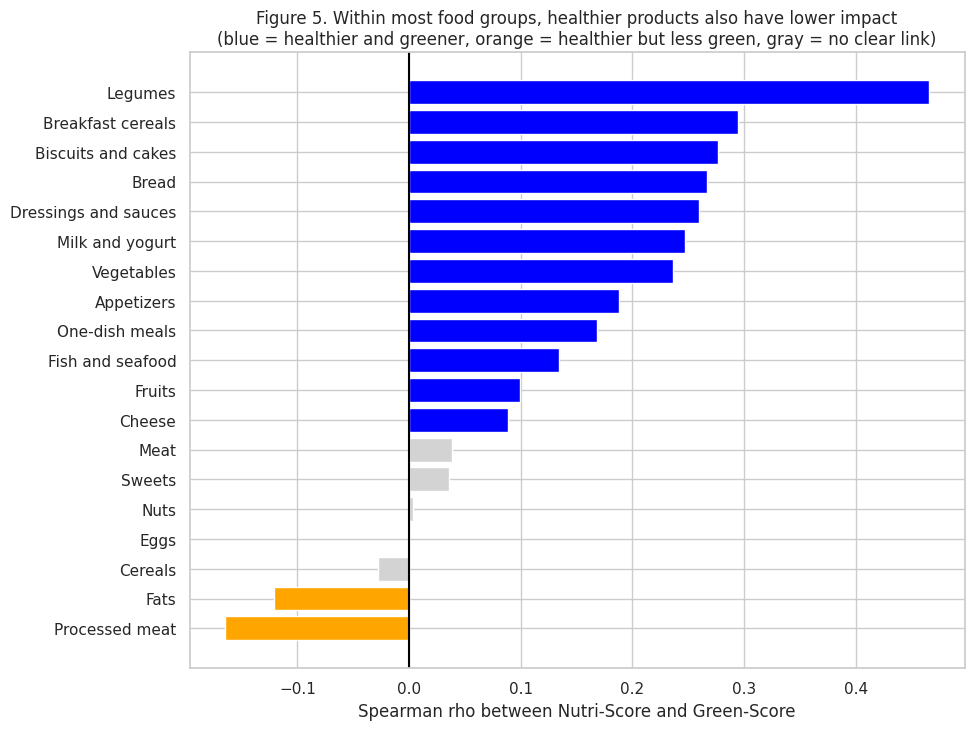

In [15]:
#Figure 5: Inside each food group, are the healthier products also the greener ones?
#Each bar is the Spearman correlation (rho) between Nutri-Score and Green-Score within one food group. Positive means healthier products also have lower impact.

rows = []
for group_name, group_data in both_cat.groupby("food_group"):
    if group_name in keep_groups and len(group_data) >= 300:
        rho, p = stats.spearmanr(group_data["nutri_number"], group_data["green_number"])
        rows.append([group_name, len(group_data), rho, p])

results = pd.DataFrame(rows, columns=["food_group", "products", "rho", "p_value"])
results = results.sort_values("rho")
display(results.set_index("food_group").round(2).T)

colors = []
for i in range(len(results)):
    if results["p_value"].iloc[i] >= 0.05:
        colors.append("lightgray")
    elif results["rho"].iloc[i] > 0:
        colors.append("blue")
    else:
        colors.append("orange")

fig, ax = plt.subplots(figsize=(10, 8))
ax.barh(results["food_group"], results["rho"], color=colors)
ax.axvline(0, color="black")
ax.set_title("Figure 5. Within most food groups, healthier products also have lower impact\n(blue = healthier and greener, orange = healthier but less green, gray = no clear link)")
ax.set_xlabel("Spearman rho between Nutri-Score and Green-Score")
plt.show()

Within each food group, is the healthier product also the greener one?


Takeaway:

In 12 of 19 food groups, healthier products also have lower impact, most strongly for legumes (rho 0.47). Five groups (cereals, eggs, nuts, sweets and meat) show no clear link, and only processed meat and fats go the other way.

food_group,"Cereals (rice, grains)",Eggs,Sweets,Biscuits and cakes,Milk and yogurt,Dressings and sauces,One-dish meals,Breakfast cereals,Legumes
products,1042.0,1295.0,1960.0,2432.0,7214.0,2603.0,474.0,2632.0,1288.0
healthy_low,57.9,91.6,6.6,5.1,59.6,20.1,66.7,60.4,89.4
healthy_high,79.7,93.7,5.3,0.6,43.5,2.6,40.1,11.7,29.7
gap,-21.8,-2.1,1.3,4.5,16.1,17.5,26.6,48.7,59.7


Average gap: 17.6
Positive groups: 7 out of 9


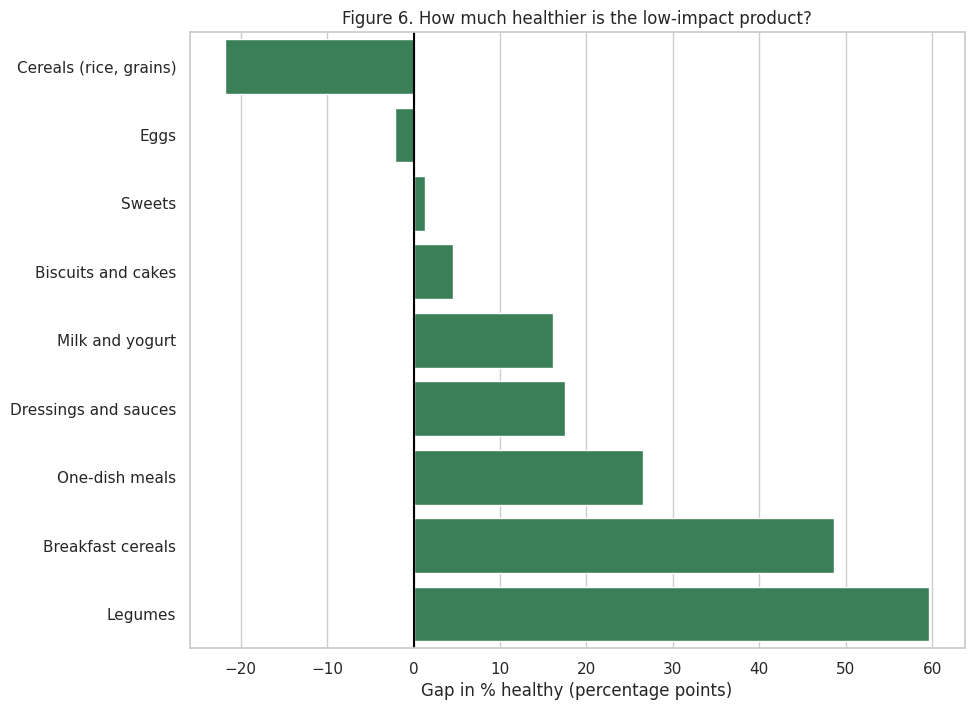

low-impact vs high-impact, same food group: 0.93x per 100 g (95% CI 0.88-0.99), 1520 vs 1399 products


In [16]:
# Figure 6. In the same food group, how much more often is the low-impact product Nutri-Score A/B?
rows = []
for group, d in g_foods.dropna(subset=["nutriscore"]).groupby("food_group"):
    low = d[d["green_score"].isin(["A", "B"])]
    high = d[d["green_score"].isin(["D", "E", "F"])]
    if len(low) >= 100 and len(high) >= 100:
        rows.append([group, len(low) + len(high), low["is_AB"].mean() * 100, high["is_AB"].mean() * 100])

gaps = pd.DataFrame(rows, columns=["food_group", "products", "healthy_low", "healthy_high"])
gaps["gap"] = gaps["healthy_low"] - gaps["healthy_high"]
gaps["food_group"] = gaps["food_group"].replace("Cereals", "Cereals (rice, grains)")
gaps = gaps.sort_values("gap")
display(gaps.set_index("food_group").round(1).T)

average_gap = np.average(gaps["gap"], weights=gaps["products"])
print("Average gap:", round(average_gap, 1))
print("Positive groups:", (gaps["gap"] > 0).sum(), "out of", len(gaps))

plt.figure(figsize=(10, 8))
sns.barplot(data=gaps, x="gap", y="food_group", color="seagreen")
plt.axvline(0, color="black")
plt.title("Figure 6. How much healthier is the low-impact product?")
plt.xlabel("Gap in % healthy (percentage points)")
plt.ylabel("")
plt.show()

# Price check: do low-impact products cost more per 100 g than high-impact ones in the same food group?
green_low = np.exp(priced.loc[priced["green_score"].isin(["A", "B"]), "log_index"])
green_high = np.exp(priced.loc[priced["green_score"].isin(["D", "E", "F"]), "log_index"])
ratio, low, high, p = price_ratio(green_low, green_high)
print(f"low-impact vs high-impact, same food group: {ratio:.2f}x per 100 g (95% CI {low:.2f}-{high:.2f}), "
      f"{len(green_low)} vs {len(green_high)} products")

**Takeaway:** Picking the low-impact product raises the chance it's healthy by about 18 percentage points on average (positive in 7 of 9 food groups), with the biggest gains in legumes (+60) and breakfast cereals (+49). It reverses for rice and grains (-22) and makes almost no difference for eggs, so the greener product is a good shortcut to the healthier one in most aisles, but not all.

**And it does not cost more:** low-impact products cost **0.93×** what high-impact products cost per 100 g in the same aisle (95% CI 0.88-0.99).

> **Smart-shopper takeaway:** the greener option is usually healthier and slightly cheaper. The exceptions are eggs and rice, where the healthy choice is not the low-impact one.

---
# Theme 3. Healthy doesn't cost more: swap within the aisle
This is the centre of the project. From here on, prices are **per 100 g**, for foods with a known package size and food group (5,752 products). Drinks are left out because tea bags, juice, and water are not comparable per 100 g.

**Caveat:** the price data is crowd-sourced, 85% from California, and 93% from one contributor. It covers 0.6% of the catalog. The results describe these (mostly Bay Area) stores and are not national price estimates. We use them to compare products within the same aisle, not to state what groceries cost.

,catalog,priced,representation
food_group,,,
Sandwiches,2.20,0.80,0.36
Fruits and vegetables,1.23,0.45,0.37
Pizza pies and quiches,2.05,1.13,0.55
Sweets,10.79,7.89,0.73
Fish and seafood,2.21,1.72,0.78
Cheese,4.67,3.69,0.79
Bread,3.61,3.34,0.92
Processed meat,2.78,2.89,1.04
Vegetables,3.80,3.96,1.04


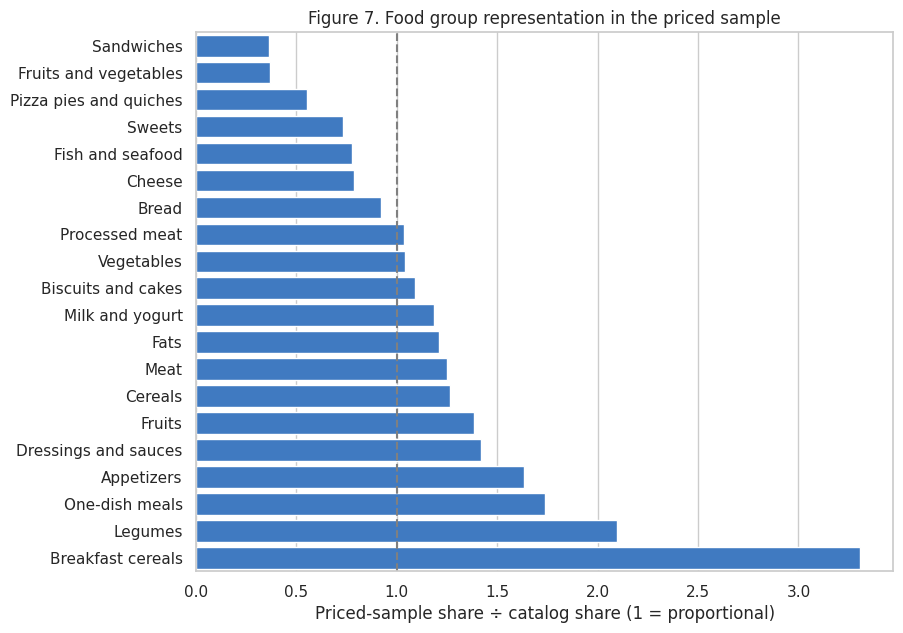

In [17]:
# Figure 7. Is each food group over- or under-represented in the priced sample?
share = pd.DataFrame({"catalog": products["food_group"].value_counts(normalize=True) * 100,
                      "priced": priced["food_group"].value_counts(normalize=True) * 100})
share = share[share["priced"] > 0]
share = share.sort_values("catalog", ascending=False).head(20)   # 20 biggest food groups
share["representation"] = share["priced"] / share["catalog"]
share = share.sort_values("representation")
display(share.round(2))

plt.figure(figsize=(9, 7))
sns.barplot(x=share["representation"], y=share.index, color="#2a78d6")
plt.axvline(1, color="gray", linestyle="--")
plt.title("Figure 7. Food group representation in the priced sample")
plt.xlabel("Priced-sample share ÷ catalog share (1 = proportional)")
plt.ylabel("")
plt.show()

Do the priced products represent the full catalog?

Takeaway: The priced sample mostly mirrors the catalog, but it leans toward ready meals and appetizers (1.6×) and away from sandwiches, sweets, cheese and fish (0.3–0.7×), reflecting where our main contributor shopped. Comparing overall averages would be misleading, so every price comparison after this is made within the same food group.

22 food groups | Spearman rho (% A/B vs price per 100 g) = -0.60, p = 0.00


,products,median_price_100g,pct_ab,aisle type
food_group,,,,
Chocolate products,154,5.99,0.00,Mostly C-E
Fish and seafood,99,3.46,55.43,Mostly Nutri-Score A/B
Biscuits and cakes,616,2.80,1.88,Mostly C-E
Nuts,87,2.51,47.56,Mostly C-E
Fats,183,2.47,39.38,Mostly C-E
Sweets,454,2.42,7.55,Mostly C-E
Processed meat,166,2.35,5.96,Mostly C-E
Cheese,212,2.31,4.89,Mostly C-E
Appetizers,200,2.22,3.19,Mostly C-E


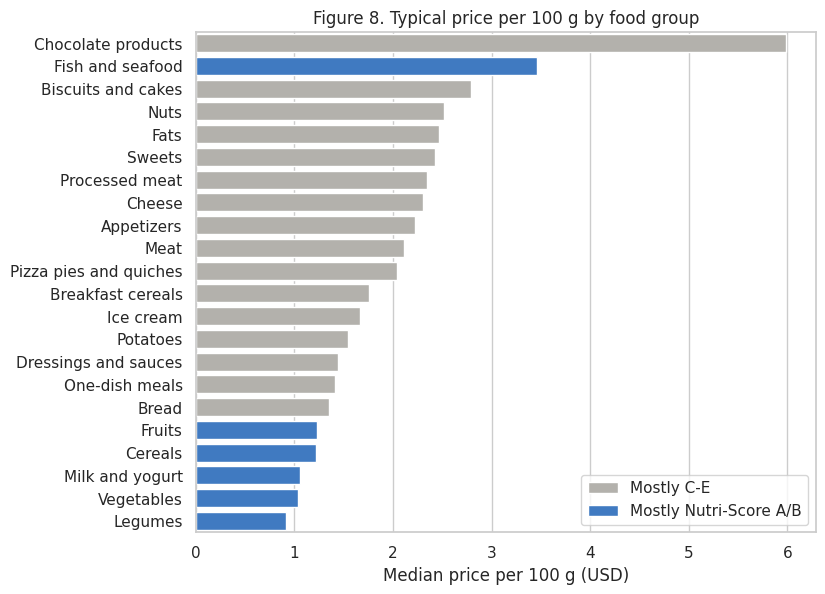

In [18]:
# Figure 8. Are the healthier aisles the more expensive ones? (median price per 100 g by food group)
aisle_price = priced.groupby("food_group").agg(products=("code", "size"),
                                               median_price_100g=("price_100g", "median"),
                                               pct_ab=("is_AB", "mean"))
aisle_price["pct_ab"] = aisle_price["pct_ab"] * 100
aisle_price = aisle_price[aisle_price["products"] >= 50].sort_values("median_price_100g", ascending=False)
aisle_price["aisle type"] = np.where(aisle_price["pct_ab"] >= 50, "Mostly Nutri-Score A/B", "Mostly C-E")

rho, p = stats.spearmanr(aisle_price["pct_ab"], aisle_price["median_price_100g"])
print(f"{len(aisle_price)} food groups | Spearman rho (% A/B vs price per 100 g) = {rho:.2f}, p = {p:.2f}")
display(aisle_price.round(2))

plt.figure(figsize=(8, 6.5))
sns.barplot(data=aisle_price, y="food_group", x="median_price_100g", hue="aisle type", dodge=False,
            palette={"Mostly Nutri-Score A/B": "#2a78d6", "Mostly C-E": "#b4b2ab"})
plt.title("Figure 8. Typical price per 100 g by food group")
plt.xlabel("Median price per 100 g (USD)")
plt.ylabel("")
plt.legend(title="", loc="lower right")
plt.show()

Are the healthier aisles more expensive?

Takeaway: Across the store, healthy food is the cheap food. Legumes, vegetables, milk, cereals and fruits cost about $1 per 100 g, while chocolate, biscuits, nuts and cheese cost $2.30–6, and aisles with more A/B products are cheaper (rho = -0.60). The belief that healthy eating is expensive likely comes from comparing per package or per item, not per 100 g.

### H4: inside an aisle, do A/B products cost more than D/E products?

,food_group,n_ab,n_de,ratio,ci_low,ci_high,p,p_adj
2,Cereals,189,69,0.481,0.394,0.588,0.000,0.000
7,One-dish meals,146,98,0.647,0.543,0.769,0.000,0.000
3,Dressings and sauces,114,384,0.663,0.557,0.788,0.000,0.000
5,Meat,43,83,0.729,0.527,1.009,0.057,0.113
0,Bread,63,41,0.774,0.545,1.099,0.150,0.240
1,Breakfast cereals,55,115,0.829,0.609,1.128,0.228,0.261
6,Milk and yogurt,145,33,0.882,0.669,1.162,0.365,0.365
4,Fats,63,56,1.150,0.915,1.445,0.229,0.261


all food groups together: A/B costs 0.83x D/E per 100 g (95% CI 0.79-0.88)


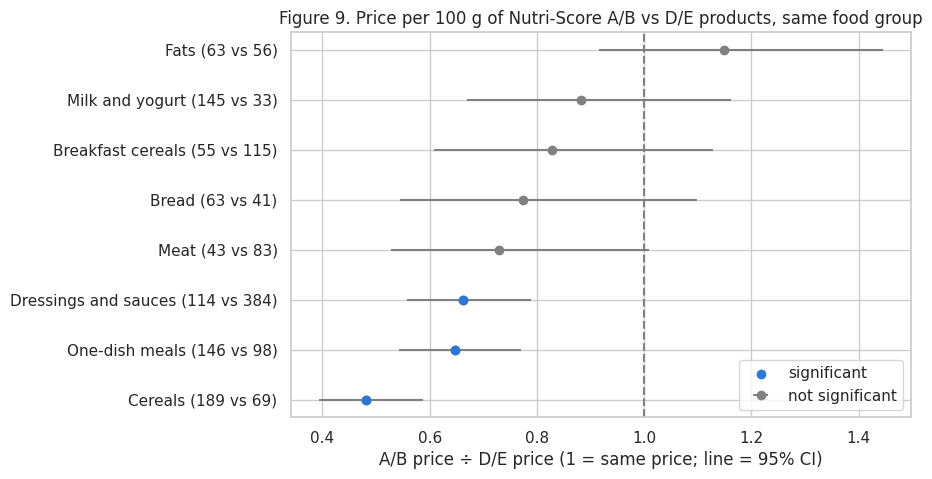

In [19]:
# Figure 9 (H4). Inside a food group, do Nutri-Score A/B products cost more per 100 g than D/E products?
rows = []
for group, d in priced.groupby("food_group"):
    ab = d.loc[d["nutriscore"].isin(["A", "B"]), "price_100g"]
    de = d.loc[d["nutriscore"].isin(["D", "E"]), "price_100g"]
    if len(ab) >= 30 and len(de) >= 30:
        ratio, low, high, p = price_ratio(ab, de)
        rows.append([group, len(ab), len(de), ratio, low, high, p])

premium = pd.DataFrame(rows, columns=["food_group", "n_ab", "n_de", "ratio", "ci_low", "ci_high", "p"])
premium = premium.sort_values("ratio")
premium["p_adj"] = stats.false_discovery_control(premium["p"])   # we test many groups, so adjust the p-values
display(premium.round(3))

# all food groups together, using each product's price index (see Table 1)
is_ab = priced["nutriscore"].isin(["A", "B"])
is_de = priced["nutriscore"].isin(["D", "E"])
ratio, low, high, p = price_ratio(np.exp(priced.loc[is_ab, "log_index"]), np.exp(priced.loc[is_de, "log_index"]))
print(f"all food groups together: A/B costs {ratio:.2f}x D/E per 100 g (95% CI {low:.2f}-{high:.2f})")

premium["label"] = premium["food_group"] + " (" + premium["n_ab"].astype(str) + " vs " + premium["n_de"].astype(str) + ")"
sig = premium[premium["p_adj"] < 0.05]

plt.figure(figsize=(8, 5))
plt.errorbar(premium["ratio"], premium["label"], xerr=[premium["ratio"] - premium["ci_low"], premium["ci_high"] - premium["ratio"]],
             fmt="o", color="gray", label="not significant")
plt.scatter(sig["ratio"], sig["label"], color="#2a78d6", zorder=3, label="significant")
plt.axvline(1, color="gray", linestyle="--")
plt.title("Figure 9. Price per 100 g of Nutri-Score A/B vs D/E products, same food group")
plt.xlabel("A/B price ÷ D/E price (1 = same price; line = 95% CI)")
plt.legend(loc="lower right")
plt.show()

Within an aisle, do A/B products cost more than D/E products?

Takeaway: Even within the same aisle, the healthier product costs less: A/B products cost 0.83× what D/E products cost per 100 g. The savings are biggest where D/E products are convenience versions of a staple, like plain rice and pasta vs noodle kits (0.48×). No aisle shows a health premium, so "swap down a grade" is advice that saves money rather than costing it.

---
# Theme 4. What shoppers pay for

These are **relative prices**, not actual dollar prices. A price index of **100** is the comparison baseline. A value of **115** means 15% higher than that baseline. Figures 10 and 11 compare products using their food-group-adjusted price index. Figure 12 shows comparisons separately by food group.

We use simple charts with labeled axes and the same two main colors throughout.

### H5: Does avoiding ultra-processed food cost more?

**Question:** When we compare products within the same food groups, are less-processed foods generally more expensive?

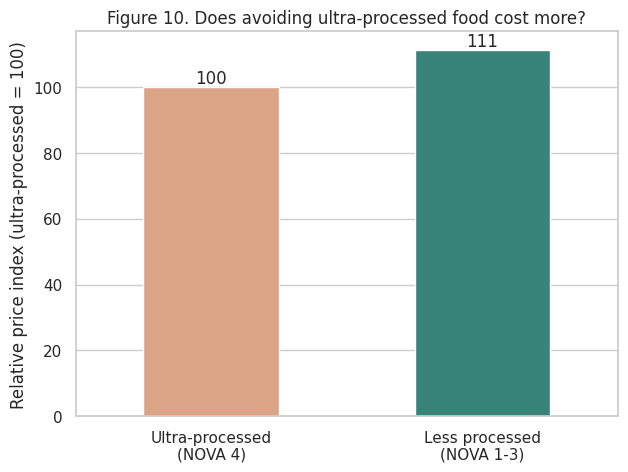

Less-processed price difference: +11.2%
95% confidence interval: +8.9% to +13.6%


In [20]:
# Figure 10: Per package, less-processed food costs about 11% more
# Compare less processed (NOVA 1-3) and ultra-processed (NOVA 4)

dh_pf = df.dropna(subset=["food_group"]).copy()
dh_pf["log_price"] = np.log(dh_pf["price"])
dh_pf["price_index"] = np.exp(dh_pf["log_price"] - dh_pf.groupby("food_group")["log_price"].transform("mean"))

less = dh_pf.loc[dh_pf["nova_group"] < 4, "price_index"]
ultra = dh_pf.loc[dh_pf["nova_group"] == 4, "price_index"]
ratio, low, high, p = price_ratio(less, ultra)

plt.figure(figsize=(7, 5))
ax = sns.barplot(x=["Ultra-processed\n(NOVA 4)", "Less processed\n(NOVA 1-3)"], y=[100, ratio * 100],
                 hue=["Ultra-processed\n(NOVA 4)", "Less processed\n(NOVA 1-3)"], palette=["#e9a079", "#2b9182"],
                 legend=False, width=0.5)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.0f")
plt.title("Figure 10. Does avoiding ultra-processed food cost more?")
plt.ylabel("Relative price index (ultra-processed = 100)")
plt.show()

print(f"Less-processed price difference: {(ratio - 1) * 100:+.1f}%")
print(f"95% confidence interval: {(low - 1) * 100:+.1f}% to {(high - 1) * 100:+.1f}%")

**Does avoiding ultra-processed food cost more?**

**Takeaway:**
Per package, less-processed products cost about 11% more than ultra-processed products in the same food group (95% CI 9–14%). This is a package price, so it mixes up the price of the food with the size of the pack, and less-processed staples like plain milk or rice often come in bigger packs. Avoiding ultra-processed food can raise the bill at the checkout, but comparing price per 100 g (Figure 9) is the fairer test of whether the food itself costs more.

### Which nutrients do shoppers pay for?

,Nutrient,Price difference
4,Salt,-7.5
3,Sugar,-3.2
2,Protein,5.1
1,Calories,10.7
0,Fat,12.7


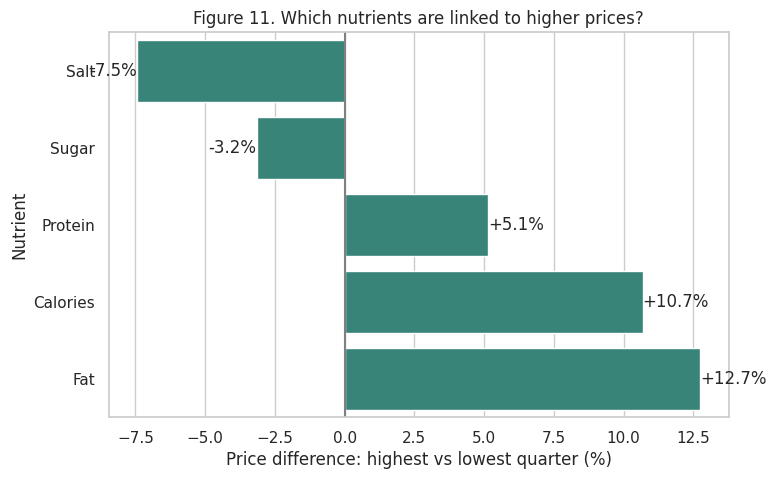

In [21]:
# Figure 11: Fattier, calorie-dense products cost more; sugary and salty ones cost less

nutrient_names = {"fat_100g": "Fat", "energy-kcal_100g": "Calories", "proteins_100g": "Protein",
                  "sugars_100g": "Sugar", "salt_100g": "Salt"}
rows = []
for col in nutrient_names:
    data = dh_pf.dropna(subset=[col])
    data = data[data.groupby("food_group")["code"].transform("size") >= 80].copy()
    data["quarter"] = data.groupby("food_group")[col].transform(lambda x: pd.qcut(x.rank(method="first"), 4, labels=False))
    ratio, low, high, p = price_ratio(data.loc[data["quarter"] == 3, "price_index"], data.loc[data["quarter"] == 0, "price_index"])
    rows.append([nutrient_names[col], (ratio - 1) * 100])

nutrient_prices = pd.DataFrame(rows, columns=["Nutrient", "Price difference"]).sort_values("Price difference")
display(nutrient_prices.round(1))

plt.figure(figsize=(8, 5))
ax = sns.barplot(data=nutrient_prices, x="Price difference", y="Nutrient", color="#2b9182")
ax.bar_label(ax.containers[0], fmt="%+.1f%%")
plt.axvline(0, color="gray")
plt.title("Figure 11. Which nutrients are linked to higher prices?")
plt.xlabel("Price difference: highest vs lowest quarter (%)")
plt.show()

**Which nutrients are linked to higher prices?**

**Takeaway:**
Within the same food group, the fattiest and most calorie-dense products cost more per package (fat +13%, calories +11%, protein +5%), while sugary and salty products cost less (sugar −3%, salt −8%). Shoppers pay a little more for richer, more filling foods, but nothing extra for sugar or salt. Cheap sugary and salty products can make less healthy choices look like better value.

### H6: Does the organic price premium vary by food group?

,food_group,n_organic,n_regular,organic_index
3,Dressings and sauces,130,1378,103.9
12,Sweets,54,868,112.0
6,Fruits,71,217,113.7
14,Vegetables,83,447,115.1
2,Cereals,68,619,121.5
13,Unsweetened beverages,100,476,134.2
8,Milk and yogurt,73,484,145.9
5,Fats,56,365,154.0


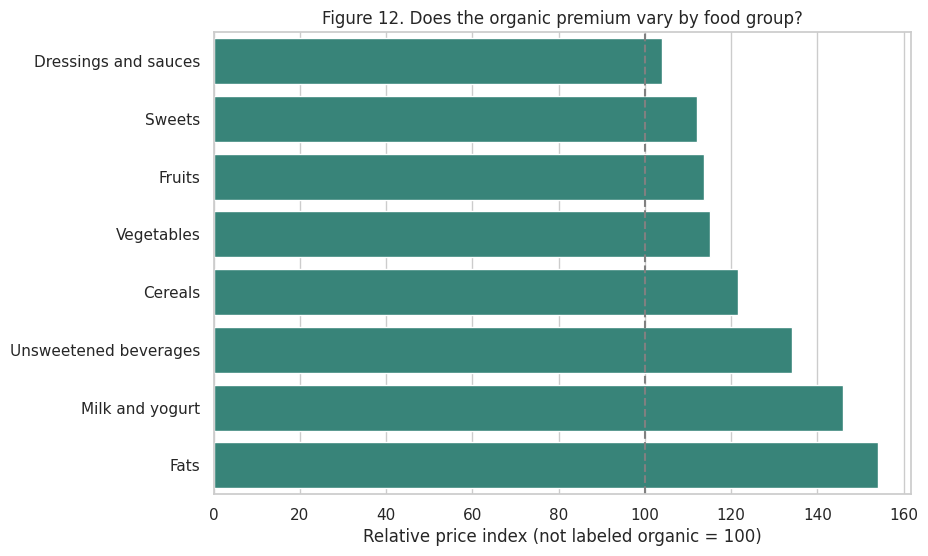

Overall organic price difference: +18.3%
95% confidence interval: +14.5% to +22.4%


In [22]:
# Figure 12 (H6). Organic price premium by food group
dh_pf["organic"] = dh_pf["product_name"].str.contains(r"\borganic", case=False, na=False)

rows = []
for group, d in dh_pf.groupby("food_group"):
    organic = d.loc[d["organic"], "price"]
    regular = d.loc[~d["organic"], "price"]
    if len(organic) >= 25 and len(regular) >= 25:
        ratio, low, high, p = price_ratio(organic, regular)
        rows.append([group, len(organic), len(regular), ratio * 100])

organic_groups = pd.DataFrame(rows, columns=["food_group", "n_organic", "n_regular", "organic_index"])
show = organic_groups.nlargest(8, "n_organic").sort_values("organic_index")   # 8 groups with the most organic products
display(show.round(1))

plt.figure(figsize=(9, 6))
sns.barplot(data=show, x="organic_index", y="food_group", color="#2b9182")
plt.axvline(100, color="gray", linestyle="--")
plt.title("Figure 12. Does the organic premium vary by food group?")
plt.xlabel("Relative price index (not labeled organic = 100)")
plt.ylabel("")
plt.show()

ratio, low, high, p = price_ratio(dh_pf.loc[dh_pf["organic"], "price_index"], dh_pf.loc[~dh_pf["organic"], "price_index"])
print(f"Overall organic price difference: {(ratio - 1) * 100:+.1f}%")
print(f"95% confidence interval: {(low - 1) * 100:+.1f}% to {(high - 1) * 100:+.1f}%")

**Does the organic premium vary by food group?**

**Takeaway**:
Organic products cost about 18% more per package than non-organic products in the same food group (95% CI 15–22%), and the premium varies a lot by aisle. It's small for sauces (+4%) and sweets (+12%), but large for milk and yogurt (+46%) and fats (+54%). Organic is a real premium in these stores, so shoppers on a budget should pick their organic buys aisle by aisle, starting where the premium is smallest.

**Conclusion:** Paying more for organic products does not automatically mean better nutritional quality. Shoppers should compare the price difference within each food group and check nutrition labels before deciding whether the extra cost is worthwhile.

---
## Theme 5. Shop the store, not just the shelf
The biggest savings we found come from *which* version and *which* store, not from which food.

### H7: store brands vs national brands

store-brand products: 655
median package size (g): store brands 453.59237 | national brands 340.1942775
price vs national brands in the same group: 0.58x (95% CI 0.54-0.61)
store brands have +10.8 pp more Nutri-Score A/B (13 groups, more A/B in 9 of them)
and -22.8 pp ultra-processed (11 groups)


food_group,Legumes,Dressings and sauces,Cheese,Vegetables,Bread,Cereals,One-dish meals,Fruits,Eggs,Sweets,Nuts,Biscuits and cakes,Fats,Milk and yogurt
n_store,34.00,60.00,50.00,63.00,20.00,57.00,32.00,42.00,25.00,30.00,38.00,21.00,27.00,25.00
n_national,111.00,712.00,162.00,165.00,172.00,373.00,451.00,123.00,23.00,424.00,49.00,595.00,156.00,235.00
ratio,0.54,0.57,0.69,0.70,0.74,0.75,0.79,0.83,0.85,0.91,0.96,1.06,1.14,1.17
ci_low,0.44,0.50,0.60,0.60,0.59,0.64,0.66,0.68,0.62,0.73,0.78,0.78,0.89,0.99
ci_high,0.67,0.65,0.79,0.82,0.92,0.89,0.94,1.00,1.18,1.14,1.19,1.43,1.46,1.39
p,0.00,0.00,0.00,0.00,0.01,0.00,0.01,0.05,0.32,0.41,0.71,0.70,0.30,0.07
q,0.00,0.00,0.00,0.00,0.02,0.00,0.02,0.09,0.41,0.48,0.71,0.71,0.41,0.11


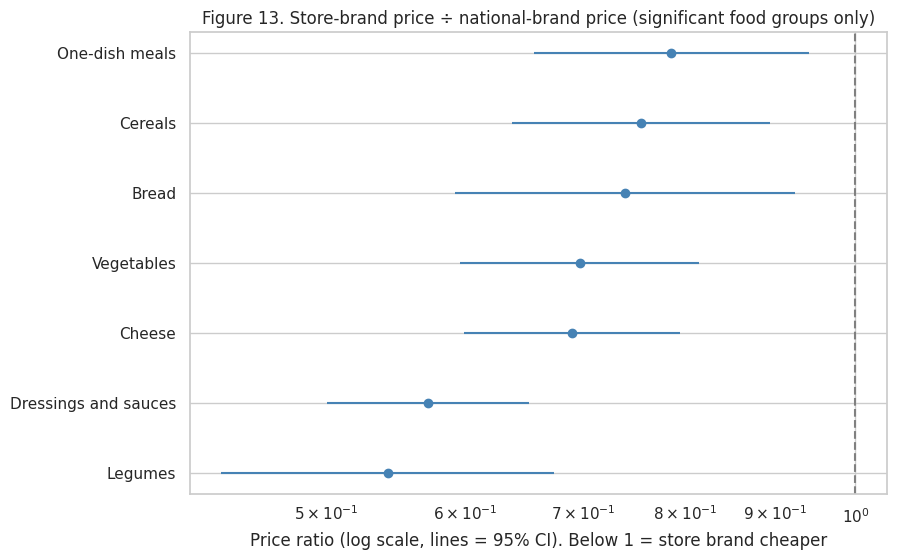

In [23]:
# Figure 13 (H7). Store brands vs national brands in the same food group
store_brands = (r"signature|lucerne|o organics|open nature|safeway|trader joe|365|whole foods|kirkland|great value|"
                r"sprouts|raley|good & gather|market pantry|simple truth|kroger|first street|nob hill|smart ?& ?final")
priced["store_brand"] = priced["brand"].str.contains(store_brands, case=False, na=False)
store = priced[priced["store_brand"]]
national = priced[~priced["store_brand"]]

# all food groups together, using the price index
ratio, low, high, p = price_ratio(np.exp(store["log_index"]), np.exp(national["log_index"]))
print("store-brand products:", len(store))
print("median package size (g): store brands", store["size_g_ml"].median(), "| national brands", national["size_g_ml"].median())
print(f"price vs national brands in the same group: {ratio:.2f}x (95% CI {low:.2f}-{high:.2f})")

# inside each food group: package price ratio, and the health gap (store brand minus national brand)
rows = []
ab_gaps, ab_n, ultra_gaps, ultra_n = [], [], [], []
for group, d in priced.groupby("food_group"):
    s = d[d["store_brand"]]
    n = d[~d["store_brand"]]
    if len(s) >= 20 and len(n) >= 20:
        ratio, low, high, p = price_ratio(s["price"], n["price"])
        rows.append([group, len(s), len(n), ratio, low, high, p])
    if s["is_AB"].count() >= 20 and n["is_AB"].count() >= 20:
        ab_gaps.append((s["is_AB"].mean() - n["is_AB"].mean()) * 100)
        ab_n.append(s["is_AB"].count())
    if s["is_ultra"].count() >= 20 and n["is_ultra"].count() >= 20:
        ultra_gaps.append((s["is_ultra"].mean() - n["is_ultra"].mean()) * 100)
        ultra_n.append(s["is_ultra"].count())

print(f"store brands have {np.average(ab_gaps, weights=ab_n):+.1f} pp more Nutri-Score A/B ({len(ab_gaps)} groups, "
      f"more A/B in {sum(g > 0 for g in ab_gaps)} of them)")
print(f"and {np.average(ultra_gaps, weights=ultra_n):+.1f} pp ultra-processed ({len(ultra_gaps)} groups)")

sb = pd.DataFrame(rows, columns=["food_group", "n_store", "n_national", "ratio", "ci_low", "ci_high", "p"])
sb = sb.sort_values("ratio")
sb["q"] = stats.false_discovery_control(sb["p"])   # adjusted p-values
display(sb.set_index("food_group").round(2).T)

# chart: only the food groups where the difference is significant
sig = sb[sb["q"] < 0.05]
plt.figure(figsize=(9, 6))
plt.errorbar(sig["ratio"], sig["food_group"], xerr=[sig["ratio"] - sig["ci_low"], sig["ci_high"] - sig["ratio"]],
             fmt="o", color="steelblue")
plt.axvline(1, color="gray", linestyle="--")
plt.xscale("log")
plt.title("Figure 13. Store-brand price ÷ national-brand price (significant food groups only)")
plt.xlabel("Price ratio (log scale, lines = 95% CI). Below 1 = store brand cheaper")
plt.show()

**Are store brands cheaper than national brands, and are they worse for you?**

**Takeaway:** Store brands are the biggest saving we found: 0.58× the price of national brands per 100 g in the same aisle, while being healthier (11 points more A/B, 23 points less ultra-processed). Part of the gap is bigger packs and plainer products, which is good news for shoppers rather than a catch. Trying the store brand first is the single easiest rule to follow.

### Same product, different store

Products priced at 2+ stores: 4323
Priciest vs cheapest store, median product: 1.14x
A quarter of products: 1.29x or more


store,Smart & Final extra!,FoodMaxx,Target,Whole Foods Market,Ava's Market and Deli,Sprouts Farmers Market,Nob Hill Foods,Safeway,Dumbo Market,Walgreens,Morton Williams,Draeger's,Mollie Stone's,Lucky
products,307.000,240.000,186.000,1090.000,244.000,371.000,1794.00,2919.000,423.000,195.000,150.000,697.000,173.000,169.000
store_index,0.892,0.895,0.924,0.974,0.975,1.003,1.01,1.016,1.017,1.032,1.045,1.083,1.097,1.106


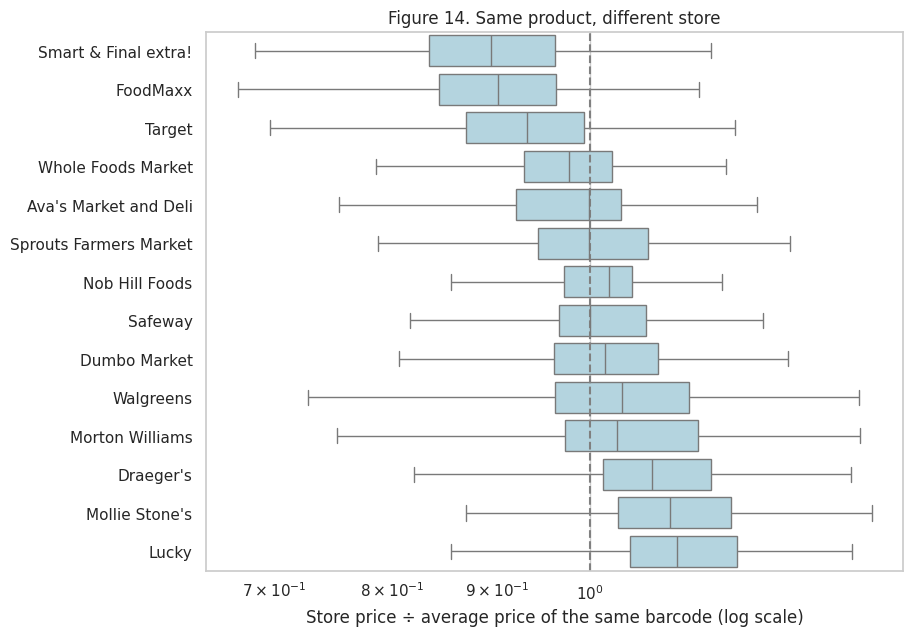

In [24]:
# Figure 14. The same product (same barcode) at different stores
# price per package is fine here because it is the identical product
prices = prices[prices["code"].isin(df["code"])]
chain = prices.groupby(["code", "store"])["regular_price"].median().reset_index()
chain = chain[chain.groupby("code")["store"].transform("nunique") >= 2].copy()   # products seen at 2+ stores

# store index = price at this store ÷ average price of the same barcode across stores (geometric mean)
# 1.25 = 25% above the product's average, 0.8 = 20% below
chain["log_price"] = np.log(chain["regular_price"])
chain["store_index"] = np.exp(chain["log_price"] - chain.groupby("code")["log_price"].transform("mean"))

spread = chain.groupby("code")["regular_price"].max() / chain.groupby("code")["regular_price"].min()
print("Products priced at 2+ stores:", chain["code"].nunique())
print(f"Priciest vs cheapest store, median product: {spread.median():.2f}x")
print(f"A quarter of products: {spread.quantile(0.75):.2f}x or more")

# stores with 150+ products
store_counts = chain["store"].value_counts()
big = chain[chain["store"].isin(store_counts[store_counts >= 150].index)]
summary = big.groupby("store")["store_index"].agg(["size", stats.gmean])
summary.columns = ["products", "store_index"]
summary = summary.sort_values("store_index")
display(summary.round(3).T)

plt.figure(figsize=(9, 7))
sns.boxplot(data=big, x="store_index", y="store", order=summary.index, color="lightblue", showfliers=False)
plt.axvline(1, color="gray", linestyle="--")
plt.xscale("log")
plt.title("Figure 14. Same product, different store")
plt.xlabel("Store price ÷ average price of the same barcode (log scale)")
plt.ylabel("")
plt.show()

**Does the same product cost more at some stores?**

**Takeaway:** The same barcode varies 14% between the cheapest and priciest store for the median product, and 29% or more for a quarter of products. Smart & Final and FoodMaxx are about 11% below average, while Whole Foods is slightly below average for identical items: its expensive reputation comes from what it stocks, not what it charges. Where you do the big weekly shop matters as much as what you buy.

### H8: are ultra-processed products promoted more?

nova_group,1.0,2.0,3.0,4.0
store,,,,
Draeger's,1.0,11.5,11.3,10.1
Nob Hill Foods,38.5,51.9,55.8,64.4
Safeway,43.2,52.4,43.9,56.5
Whole Foods Market,26.8,33.1,38.6,36.8


Average discount when on promotion, by NOVA group (%):
{1.0: 23.5, 2.0: 20.7, 3.0: 23.6, 4.0: 23.8}
Same store and food group: ultra-processed products are on promotion +2.4 pp more often (95% CI +0.6 to +4.2)


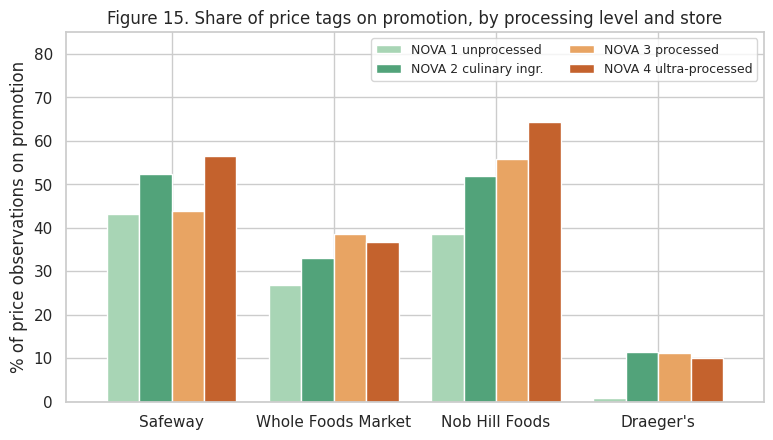

In [25]:
# Figure 15 (H8). How often are products on promotion, by processing level?
promo = prices.merge(df[["code", "nova_group", "food_group"]], on="code")
promo = promo.dropna(subset=["nova_group"])
promo["depth"] = 1 - promo["price"] / promo["regular_price"]

# % of price tags on promotion at the 4 biggest stores
top_stores = promo["store"].value_counts().head(4).index
rate = promo[promo["store"].isin(top_stores)].groupby(["store", "nova_group"])["price_is_discounted"].mean() * 100
rate = rate.unstack()   # one row per store, one column per NOVA group
display(rate.round(1))

on_sale = promo[promo["price_is_discounted"]]
print("Average discount when on promotion, by NOVA group (%):")
print((on_sale.groupby("nova_group")["depth"].mean() * 100).round(1).to_dict())

# Same store AND same food group: we take away each store+food group average (a fixed-effects regression)
# and regress promotion (1/0) on ultra-processed (1/0). b = how much more often ultra-processed is on promotion.
x = promo.dropna(subset=["food_group"]).copy()
x["cell"] = x["store"] + "|" + x["food_group"]
x = x[x.groupby("cell")["cell"].transform("size") >= 20]
x["ultra"] = (x["nova_group"] == 4).astype(float)
x["promo_flag"] = x["price_is_discounted"].astype(float)
u = x["ultra"] - x.groupby("cell")["ultra"].transform("mean")
y = x["promo_flag"] - x.groupby("cell")["promo_flag"].transform("mean")

b = (u * y).sum() / (u ** 2).sum()
se = np.sqrt(((u * (y - b * u)) ** 2).sum()) / (u ** 2).sum()   # robust standard error
print(f"Same store and food group: ultra-processed products are on promotion {b * 100:+.1f} pp more often "
      f"(95% CI {(b - 1.96 * se) * 100:+.1f} to {(b + 1.96 * se) * 100:+.1f})")

ax = rate.loc[top_stores, [1.0, 2.0, 3.0, 4.0]].plot.bar(figsize=(9, 4.8), width=0.8, rot=0,
                                                         color=["#a8d5b5", "#52a37a", "#e8a463", "#c4622d"])
ax.legend(["NOVA 1 unprocessed", "NOVA 2 culinary ingr.", "NOVA 3 processed", "NOVA 4 ultra-processed"],
          ncol=2, loc="upper right", fontsize=9)
ax.set(title="Figure 15. Share of price tags on promotion, by processing level and store",
       xlabel="", ylabel="% of price observations on promotion", ylim=(0, 85))
plt.show()

**Are ultra-processed products on promotion more often?**

**Takeaway:**
Ultra-processed products look heavily promoted (64% vs 39% of price tags at Nob Hill), but most of that is because snack and sweet aisles are promoted more overall. Within the same store and aisle, the gap shrinks to +2.4 points: small but real. Discounts are the same size (about 24%) at every processing level, so a sale tag in the snack aisle is a nudge toward the aisle, not a better deal.

**Not supported once the aisle is held fixed.**

At Nob Hill and Safeway, ultra-processed products carry promotion tags more often (64% vs 39% for NOVA 1 at Nob Hill). But within the same store **and** aisle, the difference is small and not significant (+2.2 pp, CI −1.8 to +6.1), and goes the other way in about half of the pairs. Promotions follow the aisle: snack and sweet aisles are promoted heavily, and those aisles are mostly ultra-processed.

> **Smart-shopper takeaway:**
> - Reach for the store brand first.
> - Do the big shop at a cheaper store.
> - Treat a sale tag in the snack aisle as a nudge, not a saving.

---
## The smart-shopper playbook (conclusions)
| # | Rule | Evidence from this project | What it is worth | How sure we are |
|---|---|---|---|---|
| 1 | **Compare within the aisle** | The aisle explains more of the Nutri-Score than the brand (R² 0.40 vs 0.29) | Sets up every rule below | High (85,172 products) |
| 2 | **Read the price per 100 g** | Package price hides size; store brands come in bigger packs (454 g vs 340 g) | Makes the savings below visible | High |
| 3 | **Swap down a grade, not up in price** | A/B costs 0.83× D/E per 100 g in the same aisle; no aisle shows a health premium | About 17% less per 100 g | Medium (local prices) |
| 4 | **Buy plain staples; pay for quality only in treats** | Less processing is cheaper in milk/yogurt, cereals, and breakfast cereals, and dearer in fats, chocolate, and biscuits | 37-57% less in staples | Medium |
| 5 | **Choose the greener option** | +18 pp more A/B; 0.93× the price per 100 g | About 7% less, and healthier | Medium (Green-Score covers 6%) |
| 6 | **Try the store brand first** | 0.58× per 100 g; more A/B in 10 of 14 aisles | About 42% less per 100 g (part is pack size) | Medium-high |
| 7 | **Know your store** | Median 14% gap for the same barcode across stores | 8-11% at the cheaper stores | Medium (Bay Area stores) |
| 8 | **Don't follow sale tags into the snack aisle** | Promotions follow the aisle, not the product's health | Avoids impulse spending | Low-medium (not significant within aisle) |

**Bottom line for shoppers:** in the stores we could measure, eating better is mostly a matter of *how* you compare, not *how much* you spend.

## Risks
Risks for a shopper following these rules, or for an app that gives this advice:
- **Price per 100 g favours big packs.** A larger pack is only cheaper if you finish it, so waste can cancel the saving.
- **Cheap per 100 g can mislead.** Sugary and dry products look cheap per 100 g (Theme 4), so price should never be the only signal.
- **Nutri-Score has blind spots.** It is calculated per 100 g, not per portion, and it does not cover additives, so a recommended swap is a better choice, not necessarily a perfect one.
- **Prices go stale.** Shelf prices and promotions change weekly, so advice based on old prices can be wrong at the shelf.
- **Bad swaps erode trust.** Matching by category tags can suggest products that are not real substitutes (e.g. crackers for cookies). A few poor suggestions could make shoppers ignore the good ones.
- **Gaming and privacy.** If an app rewards price uploads, some users may upload fake prices to earn points. Receipts and store locations are also personal data.

## Limitations
- **Local, concentrated price data:** 85% of price observations are from California and 93% from one contributor, so results describe these stores, not U.S. prices.
- **Small priced sample:** 5,752 foods have both a price per 100 g and a food group (0.6% of the catalog), and package size is known for only 43% of priced products.
- **Coarse matching:** comparisons are within official food groups, which still mix different products (e.g. milk gallons and yogurt cups in "Milk and yogurt"). Part of each gap may be product mix rather than a true price difference.
- **Approximate flags:** store brands are identified by brand name, and organic status by label tags (missing for 82% of products).
- **Scores are not missing at random:** popular, well-documented products are more likely to have a Nutri-Score, Green-Score, and price.
- **Associations, not causes:** we show which products cost more, not why. Brand, packaging, and store strategy all play a part.

## Challenges
- **No second price region.** Commercial price APIs and scanner data cost money, and scraping retailer websites breaks their terms of use, so we stayed with Open Prices and kept every price claim to within-aisle comparisons.
- **Package size.** The first data pull had no package size. The v2 pull added it, but some sizes were clearly wrong (e.g. "1 g" of peanut butter for $24), so we kept sizes between 20 g and 5 kg and prices between $0.05 and $50 per 100 g.
- **Categories.** Each product's category list starts with a very broad parent, so the first category was useless for grouping. We switched to the official Open Food Facts food groups.
- **Messy crowd-sourced fields.** Barcodes lost leading zeros when read as numbers, placeholders such as "unknown" looked like real values, and some nutrients were impossible (over 100 g per 100 g).
- **Downloading the data.** Hugging Face returned HTTP 429 (too many requests) when we streamed the parquet files, so the pull notebook downloads them once and reads them locally.

---
## Next steps: a gamified swap app built on Open Prices
The rules above only help if shoppers can use them at the shelf, in a few seconds. Our next step is a phone app (**SmartCart**) that turns this notebook into instant, personal advice, and turns shoppers into contributors to the open price data it runs on.

**What the shopper sees**
| Feature | What it does | Rule it applies |
|---|---|---|
| Scan and price check | Scan a barcode and see the price per 100 g, rated against the aisle median (e.g. "1.2× the aisle average") | 1, 2 |
| Better swap | Up to 3 similar products in the same aisle that are healthier **and** cheaper per 100 g | 3, 4, 5, 6 |
| Store tip | "Seen for $X less at Store Y" for the same barcode | 7 |
| Sale-tag check | Flags promotions on D/E or ultra-processed products | 8 |
| Points and streaks | Points for every swap (more for bigger health gains and savings), weekly savings total, streaks, and badges such as "Store-brand scout" or "Aisle swapper" | Keeps the habit going |
| Price hunter | Points for photographing price tags, which go into Open Prices | Fixes our biggest data limitation |

**What runs in the backend**
| Layer | What it does | Built from |
|---|---|---|
| Data | Nightly import of Open Food Facts products and Open Prices observations | Our pull notebook |
| Cleaning | Barcode fixes, regular prices, package sizes, price per 100 g | Section 2 of this notebook |
| Price index | Aisle medians and each product's price index; store index for the same barcode | Themes 3 and 5 |
| Swap engine | Same aisle, better Nutri-Score, lower price per 100 g, similar categories; ranked by points | Prototype below |
| Feedback loop | Swaps accepted or rejected improve the matching; new price photos are checked against recent prices before they count | Protects against bad swaps and fake prices |

**How we would measure success:** share of scans that get a swap, swap acceptance rate, dollars saved per shopper per week, change in the average Nutri-Score of scanned baskets, and new prices contributed per user.

### Prototype: the swap engine on our data

In [26]:
# Prototype of the app's swap logic (only Open Food Facts + Open Prices)
# For a scanned product: (1) its price per 100 g vs its aisle, (2) swaps that are healthier AND cheaper per 100 g
# and similar enough to replace it, (3) the cheapest store we have seen it at.
# Points (the game part): 10 points per Nutri-Score grade gained + 1 point per 2% saved.
priced["tags"] = priced["categories_tags"].fillna("").str.split("|").map(set)

def find_swaps(item):
    # same food group, better Nutri-Score, lower price per 100 g
    aisle = priced[priced["food_group"] == item["food_group"]]
    swaps = aisle[(aisle["nutriscore"] < item["nutriscore"]) & (aisle["price_100g"] < item["price_100g"])].copy()
    # similarity = category tags in common ÷ all tags of the two products (1 = same categories)
    swaps["similarity"] = [len(t & item["tags"]) / max(len(t | item["tags"]), 1) for t in swaps["tags"]]
    return swaps[swaps["similarity"] >= 0.5]

# Demo: a shopper scans a box of Cinnamon Toast Crunch
item = priced[priced["product_name"] == "Cinnamon Toast Crunch"].iloc[0]
aisle_median = priced.loc[priced["food_group"] == item["food_group"], "price_100g"].median()
print(f"Scanned: {item['product_name']} ({item['brand']}) | {item['food_group']} | Nutri-Score {item['nutriscore']}")
print(f"Price: ${item['price_100g']:.2f} per 100 g = {item['price_100g'] / aisle_median:.1f}x the aisle median (${aisle_median:.2f})")

seen = prices[prices["code"] == item["code"]].groupby("store")["regular_price"].median().sort_values()
if len(seen) > 1:
    print(f"Cheapest store seen: {seen.index[0]} (${seen.iloc[0]:.2f} vs ${seen.iloc[-1]:.2f} at {seen.index[-1]})")

grade = {"A": 0, "B": 1, "C": 2, "D": 3, "E": 4}
swaps = find_swaps(item)
swaps["saving_pct"] = (1 - swaps["price_100g"] / item["price_100g"]) * 100
swaps["points"] = ((grade[item["nutriscore"]] - swaps["nutriscore"].map(grade)) * 10 + swaps["saving_pct"] / 2).round()
swaps = swaps.sort_values(["similarity", "points"], ascending=False)
display(swaps[["product_name", "brand", "nutriscore", "price_100g", "saving_pct", "similarity", "points"]].head(5).round(2))

# How often would the app find a swap? Check every D/E product in the price set
de = priced[priced["nutriscore"].isin(["D", "E"])]
found = [len(find_swaps(row)) > 0 for _, row in de.iterrows()]
print(f"\nThe app finds at least one similar, healthier and cheaper swap for {np.mean(found):.0%} "
      f"of Nutri-Score D/E products ({sum(found)} of {len(de)})")

Scanned: Cinnamon Toast Crunch (General Mills) | Breakfast cereals | Nutri-Score C
Price: $2.05 per 100 g = 1.2x the aisle median ($1.76)


,product_name,brand,nutriscore,price_100g,saving_pct,similarity,points
19284,Shredded Wheat,Post,A,1.37,33.33,1.00,37.0
12114,Fiber One Cereal,Fiber One,B,1.53,25.55,1.00,23.0
7164,Bite-size shredded wheat,Winco foods,A,0.46,77.39,0.86,59.0
533,Quick Cooking Hot Wheat Cereal,Malt-O-Meal,A,0.75,63.27,0.86,52.0
9247,Organic Bare Multigrain Cereal With Flax,Better Oats,A,0.74,63.77,0.86,52.0



The app finds at least one similar, healthier and cheaper swap for 89% of Nutri-Score D/E products (2241 of 2521)


For a box of Cinnamon Toast Crunch at $2.05 per 100 g (1.2× the breakfast-cereal median), the prototype suggests Post Shredded Wheat (A, 33% cheaper per 100 g) and Fiber One (B, 26% cheaper). Across the price set, it finds at least one healthier, cheaper, similar swap for **89% of Nutri-Score D/E products**. The category tags are coarse, so some suggestions are not real substitutes. Better product matching is the first thing to improve before a real launch.

**Other next steps**
1. **More prices, more places:** the team scans prices at Boston stores into Open Prices, which gives a second region at no cost and joins automatically by barcode.
2. **Better matching:** use finer categories and product names to pair true substitutes, and compare price per serving as well as per 100 g.
3. **Test with shoppers:** a small pilot (e.g. 20 students over 4 weeks) to measure swap acceptance and savings before building the full app.

## References
- Open Food Facts. *Product database* (food.parquet). Hugging Face, https://huggingface.co/datasets/openfoodfacts/product-database. ODbL 1.0.
- Open Food Facts. *Open Prices*. Hugging Face, https://huggingface.co/datasets/openfoodfacts/open-prices. ODbL 1.0.
- Open Food Facts. *Food-group taxonomy*, https://github.com/openfoodfacts/openfoodfacts-server/tree/main/taxonomies.
- Santé publique France. *Nutri-Score*, https://www.santepubliquefrance.fr/en/nutri-score.
- Monteiro, C. A., et al. (2019). Ultra-processed foods: what they are and how to identify them. *Public Health Nutrition*, 22(5), 936-941.
- Open Food Facts. *Green-Score (formerly Eco-Score)*, https://world.openfoodfacts.org/green-score.
- Benjamini, Y., & Hochberg, Y. (1995). Controlling the false discovery rate. *Journal of the Royal Statistical Society B*, 57(1), 289-300.

## GenAI Disclosure

We used Claude (Anthropic), ChatGPT (OpenAI), Codex, and Gemini as coding, debugging, and writing assistants.
AI helped us understand code structure, explore unfamiliar analytical methods and chart types, and generate initial drafts that we reviewed, adapted, and customized for our datasets and research questions.

### Where we used it?

**Data pull:** Claude helped write the original code to download Hugging Face data using DuckDB (B02-Data-Pull-v2.ipynb).
Cleaning and chart code: AI provided guidance on code structure and initial drafts for cleaning and visualizations, particularly unfamiliar chart types. We adapted the drafts to our datasets, refined their appearance, and added analytical layers.

Theme 1 (Aashna): Used claude to troubleshoot and explore alternative approaches to refine visualizations. I reviewed and adapted suggestions to improve the presentation of findings while retaining responsibility for the analysis.
Theme 2 (Gauri): Claude provided initial code structures for unfamiliar chart types, helping Gauri construct graphs that were subsequently iterated on and adapted to our project, datasets, and analysis. AI also helped troubleshoot cluttered or unclear visualizations, improve their presentation, and refine insights and conclusions to align with the notebook's narrative. Selected changes included A+B totals on Figure 3, quadrant labels on Figure 4, significance-based coloring on Figure 5, and a gap bar chart on Figure 6.
Theme 3 (Peter): Peter used Claude and Codex to brainstorm analytical questions, discuss possible interpretations of data patterns, and get feedback on charts and analytical approaches. AI also helped debug and refine selected code, improve visualizations, explain Python syntax, and improve the clarity and grammar of team-written drafts. Suggestions were reviewed and discussed with the team rather than used to generate the entire notebook or make final decisions.
Theme 4 (Dhruv): ChatGPT assisted with Python coding, debugging, and improving the visual presentation of Figures 10–12, which examined food processing, nutrient content, and organic price premiums. AI also helped refine key takeaways and conclusions, which were reviewed and incorporated into the team's final analysis.
Theme 5 (Alex): Claude helped fix minor visualization details and suggest ways to communicate the main ideas more clearly. During integration into the main notebook, Gemini helped Alex identify errors and troubleshoot solutions.

### Writing, analysis, and app prototype:
AI explained code and concepts such as .T, ax.text, Spearman's rho, and weighted averages; suggested hypothesis framing, figure questions, and takeaways; flagged inconsistencies with the rubric and cell outputs; and provided an initial code draft for the swap-app prototype.

##What we decided ourselves?
We determined our research questions, hypotheses, analytical approach, and results to report. We selected which AI suggestions to keep or reject, adapted the code and visualizations, and made all final decisions about interpretations and conclusions.How we checked the AI output
Re-ran the notebook to verify reported numbers and confirmed Theme 2's revised code matched the original results.
Investigated surprising findings by examining actual products, including unexpected cereal classifications and ultra-processed fats.
Reviewed extreme price-per-100 g values before setting cut-offs and evaluated swap suggestions for weak matches.
Compared findings against group medians and counts and reviewed AI-generated code and writing as a team.